## Step-1.Business and Data Understanding

### Business Problem
Swiggy processes millions of food-delivery journeys across hundreds of cities every month. Accurate Estimated Time of Arrival (ETA) at order placement and during delivery is core to the customer experience — it affects conversion, cancellations, ratings, and retention. Today’s ETA accuracy suffers from many sources of uncertainty: highly variable traffic patterns, weather events, restaurant preparation variability, rider behaviour and skill, order batching/multiple deliveries, and city-specific operational constraints. Inaccurate ETAs cause:

Reduced customer trust and lower repeat orders.

Increased cancellations and refund costs.

Higher support volume and operational interventions.

Sub-optimal rider allocation and increased rider idle or overtime costs.

### Problem Statement
Swiggy’s objective is to predict the delivery time (minutes) per order at the moment of order placement (and update it dynamically), with business-grade accuracy and uncertainty estimates so the platform can

 (a) show reliable ETAs to customers
 
 (b) optimize rider allocation.
 
Build a production-ready, scalable Machine Learning system that predicts per-order delivery time (in minutes) using real-time and historical features (order, rider, restaurant, geospatial, traffic, weather, and temporal signals). The system must produce:


### Data Understanding

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error,root_mean_squared_error,mean_absolute_error,r2_score
from sklearn.preprocessing import OneHotEncoder,OrdinalEncoder,StandardScaler,PowerTransformer,MinMaxScaler,RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.tree import  DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import chi2,VarianceThreshold,SelectKBest,RFECV,RFE
from sklearn.model_selection import train_test_split,GridSearchCV,KFold,cross_val_score
from xgboost import XGBRegressor
from mlxtend.plotting import plot_learning_curves
from mlxtend.evaluate import bias_variance_decomp
import optuna
import pickle

In [34]:
df=pd.read_csv(r"C:\Users\Ganesh\Downloads\swiggy_demographic.csv")

In [4]:
df.head()

,rider_id,age,ratings,restaurant_latitude,restaurant_longitude,delivery_latitude,delivery_longitude,order_date,weather,traffic,...,time_taken,city_name,order_day,order_month,order_day_of_week,is_weekend,pickup_time_minutes,order_time_hour,order_time_of_day,distance
0,INDORES13DEL02,37.0,4.9,22.745049,75.892471,22.765049,75.912471,2022-03-19,sunny,high,...,24,INDO,19,3,saturday,1,15.0,11.0,morning,3.025149
1,BANGRES18DEL02,34.0,4.5,12.913041,77.683237,13.043041,77.813237,2022-03-25,stormy,jam,...,33,BANG,25,3,friday,0,5.0,19.0,evening,20.183530
2,BANGRES19DEL01,23.0,4.4,12.914264,77.678400,12.924264,77.688400,2022-03-19,sandstorms,low,...,26,BANG,19,3,saturday,1,15.0,8.0,morning,1.552758
3,COIMBRES13DEL02,38.0,4.7,11.003669,76.976494,11.053669,77.026494,2022-04-05,sunny,medium,...,21,COIMB,5,4,tuesday,0,10.0,18.0,evening,7.790401
4,CHENRES12DEL01,32.0,4.6,12.972793,80.249982,13.012793,80.289982,2022-03-26,cloudy,high,...,30,CHEN,26,3,saturday,1,15.0,13.0,afternoon,6.210138


In [16]:
df.dtypes

age                    float64
ratings                float64
weather                 object
traffic                 object
vehicle_condition        int64
type_of_order           object
type_of_vehicle         object
multiple_deliveries    float64
festival                object
city_type               object
time_taken               int64
city_name               object
order_day                int64
order_month              int64
order_day_of_week       object
is_weekend               int64
pickup_time_minutes    float64
order_time_hour        float64
order_time_of_day       object
distance               float64
dtype: object

In [5]:
df.drop(columns=['rider_id','order_date','restaurant_latitude', 'restaurant_longitude',
       'delivery_latitude', 'delivery_longitude','city_name'],inplace=True)

In [17]:
df['is_weekend'].unique()

array([1, 0])

In [14]:
df.describe(include='all')

,age,ratings,weather,traffic,vehicle_condition,type_of_order,type_of_vehicle,multiple_deliveries,festival,city_type,time_taken,city_name,order_day,order_month,order_day_of_week,is_weekend,pickup_time_minutes,order_time_hour,order_time_of_day,distance
count,43648.000000,43594.000000,44977,44992,45502.000000,45502,45502,44509.000000,45274,44304,45502.000000,45502,45502.000000,45502.000000,45502,45502.000000,43862.000000,43862.000000,45502,41872.000000
unique,NaN,NaN,6,4,NaN,4,4,NaN,2,3,NaN,22,NaN,NaN,7,NaN,NaN,NaN,5,NaN
top,NaN,NaN,fog,low,NaN,snack,motorcycle,NaN,no,metropolitian,NaN,JAP,NaN,NaN,wednesday,NaN,NaN,NaN,night,NaN
freq,NaN,NaN,7654,15477,NaN,11512,26427,NaN,44380,34029,NaN,3439,NaN,NaN,7077,NaN,NaN,NaN,18312,NaN
mean,29.555008,4.635287,NaN,NaN,1.019406,NaN,NaN,0.744928,NaN,NaN,26.297591,NaN,13.811657,2.980726,NaN,0.274867,9.989399,17.423966,NaN,9.719296
std,5.761482,0.313827,NaN,NaN,0.835229,NaN,NaN,0.572488,NaN,NaN,9.386419,NaN,8.709540,0.546031,NaN,0.446452,4.087516,4.817856,NaN,5.602890
min,20.000000,2.500000,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,10.000000,NaN,1.000000,2.000000,NaN,0.000000,5.000000,0.000000,NaN,1.465067
25%,25.000000,4.500000,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,19.000000,NaN,6.000000,3.000000,NaN,0.000000,5.000000,15.000000,NaN,4.657655
50%,30.000000,4.700000,NaN,NaN,1.000000,NaN,NaN,1.000000,NaN,NaN,26.000000,NaN,13.000000,3.000000,NaN,0.000000,10.000000,19.000000,NaN,9.193014
75%,35.000000,4.900000,NaN,NaN,2.000000,NaN,NaN,1.000000,NaN,NaN,32.000000,NaN,20.000000,3.000000,NaN,1.000000,15.000000,21.000000,NaN,13.680920


#### Problem:Regression cuz output column is time taken which can be continous value.

In [27]:
df.shape

(45502, 19)

In [28]:
df.columns

Index(['age', 'ratings', 'weather', 'traffic', 'vehicle_condition',
       'type_of_order', 'type_of_vehicle', 'multiple_deliveries', 'festival',
       'city_type', 'time_taken', 'order_day', 'order_month',
       'order_day_of_week', 'is_weekend', 'pickup_time_minutes',
       'order_time_hour', 'order_time_of_day', 'distance'],
      dtype='object')

In [29]:
df.dtypes

age                    float64
ratings                float64
weather                 object
traffic                 object
vehicle_condition        int64
type_of_order           object
type_of_vehicle         object
multiple_deliveries    float64
festival                object
city_type               object
time_taken               int64
order_day                int64
order_month              int64
order_day_of_week       object
is_weekend               int64
pickup_time_minutes    float64
order_time_hour        float64
order_time_of_day       object
distance               float64
dtype: object

In [30]:
df.isna().sum()

age                    1854
ratings                1908
weather                 525
traffic                 510
vehicle_condition         0
type_of_order             0
type_of_vehicle           0
multiple_deliveries     993
festival                228
city_type              1198
time_taken                0
order_day                 0
order_month               0
order_day_of_week         0
is_weekend                0
pickup_time_minutes    1640
order_time_hour        1640
order_time_of_day         0
distance               3630
dtype: int64

In [31]:
df.describe()

,age,ratings,vehicle_condition,multiple_deliveries,time_taken,order_day,order_month,is_weekend,pickup_time_minutes,order_time_hour,distance
count,43648.000000,43594.000000,45502.000000,44509.000000,45502.000000,45502.000000,45502.000000,45502.000000,43862.000000,43862.000000,41872.000000
mean,29.555008,4.635287,1.019406,0.744928,26.297591,13.811657,2.980726,0.274867,9.989399,17.423966,9.719296
std,5.761482,0.313827,0.835229,0.572488,9.386419,8.709540,0.546031,0.446452,4.087516,4.817856,5.602890
min,20.000000,2.500000,0.000000,0.000000,10.000000,1.000000,2.000000,0.000000,5.000000,0.000000,1.465067
25%,25.000000,4.500000,0.000000,0.000000,19.000000,6.000000,3.000000,0.000000,5.000000,15.000000,4.657655
50%,30.000000,4.700000,1.000000,1.000000,26.000000,13.000000,3.000000,0.000000,10.000000,19.000000,9.193014
75%,35.000000,4.900000,2.000000,1.000000,32.000000,20.000000,3.000000,1.000000,15.000000,21.000000,13.680920
max,39.000000,5.000000,3.000000,3.000000,54.000000,31.000000,4.000000,1.000000,15.000000,23.000000,20.969489


In [6]:
X=df.drop(columns=['time_taken'])
y=df['time_taken']

In [33]:
X.shape

(45502, 18)

In [34]:
y.shape

(45502,)

##### Outliers are reasonable so no need to remove or clip.

## Step-2:Data Preprocessing

#### Train Test Split

In [7]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=23)

In [8]:
X_train.shape

(36401, 18)

In [37]:
X_test.shape

(9101, 18)

In [38]:
y_train.shape

(36401,)

In [39]:
y_test.shape

(9101,)

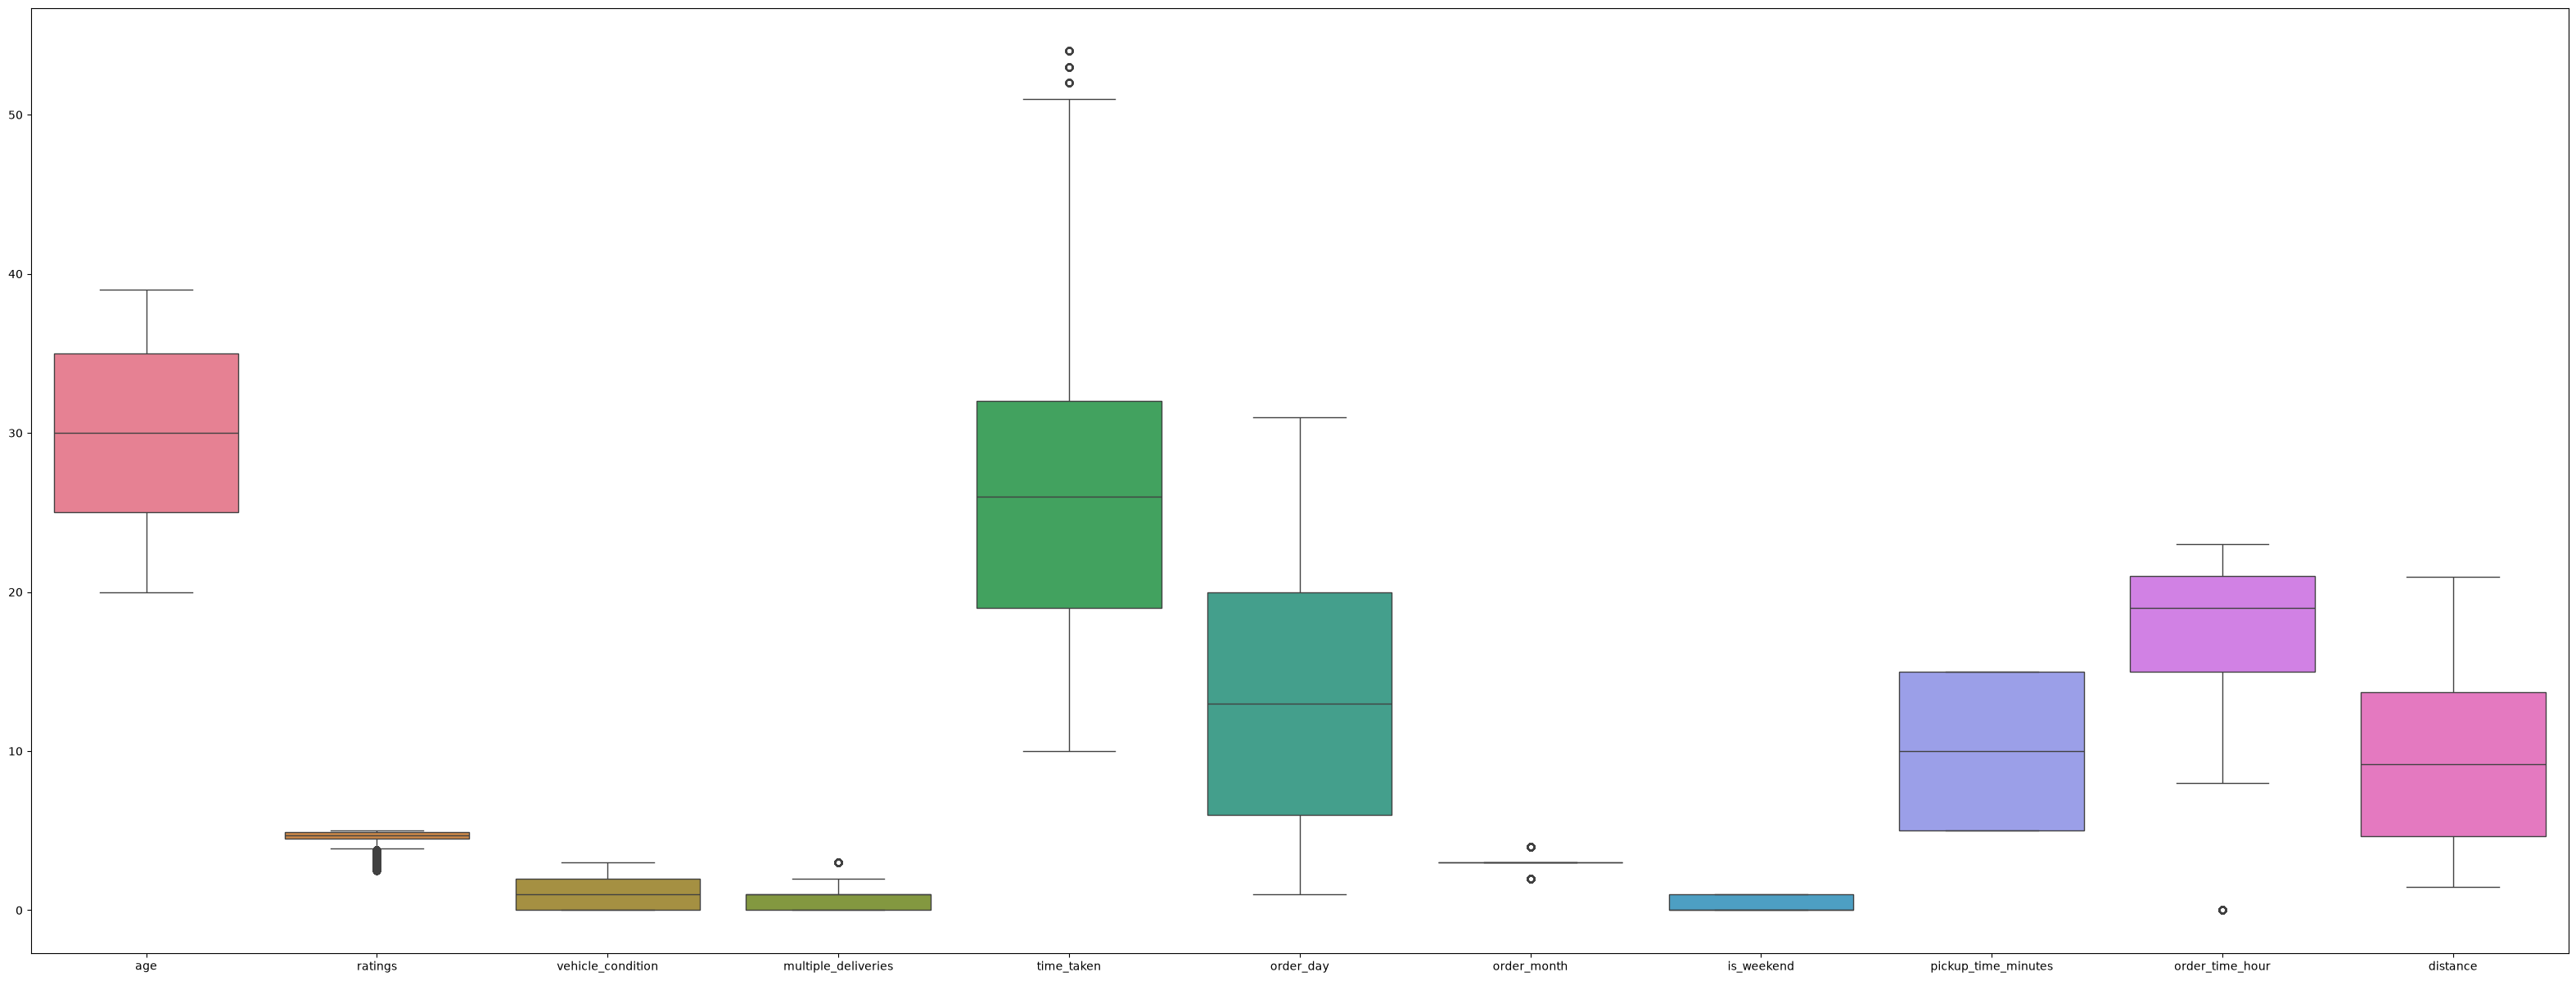

In [40]:
plt.figure(figsize=(40,15))
sns.boxplot(df);

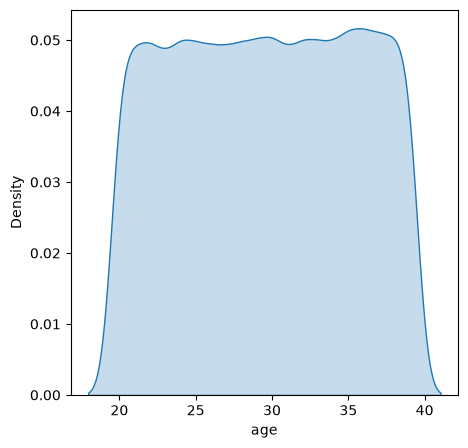

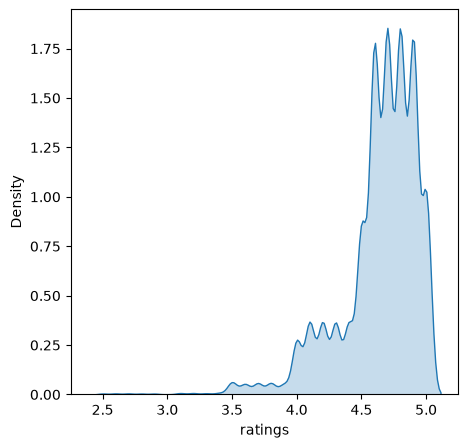

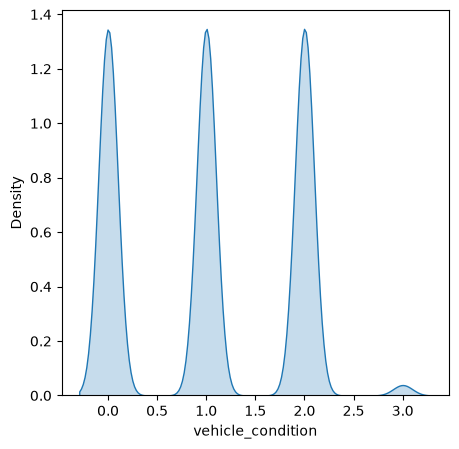

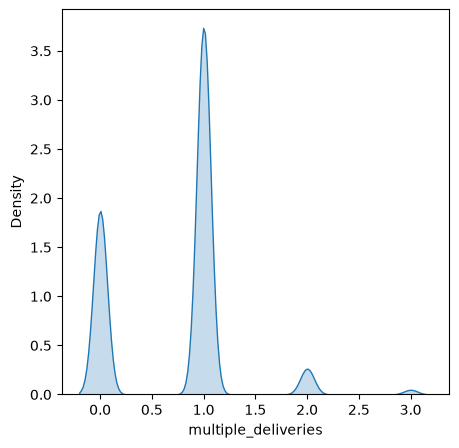

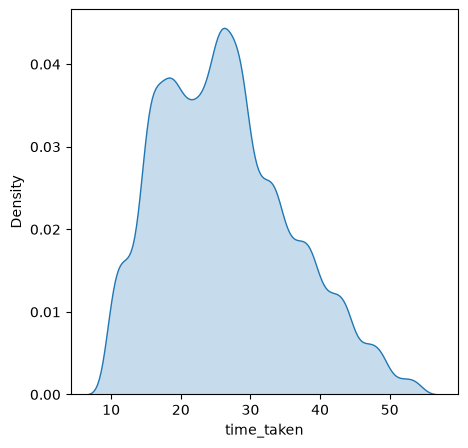

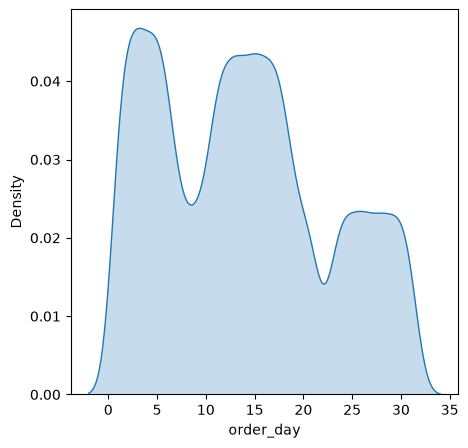

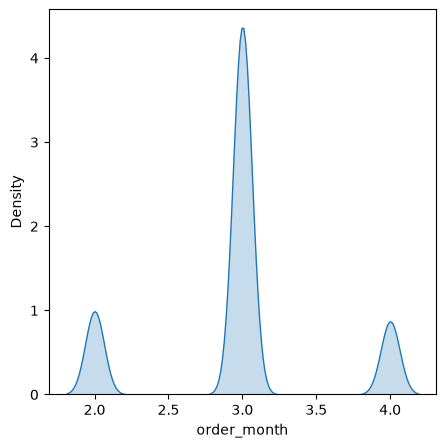

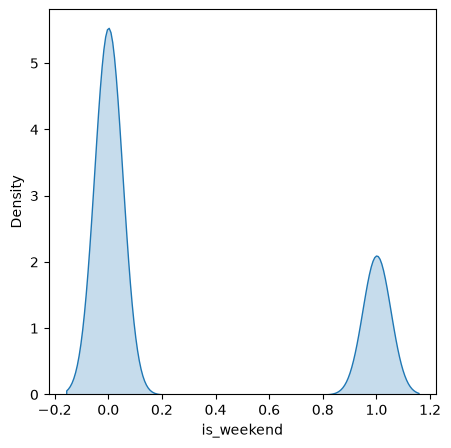

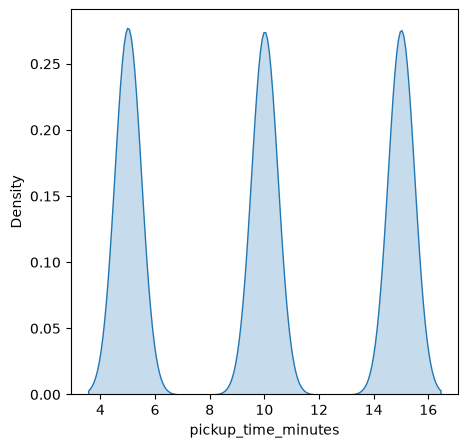

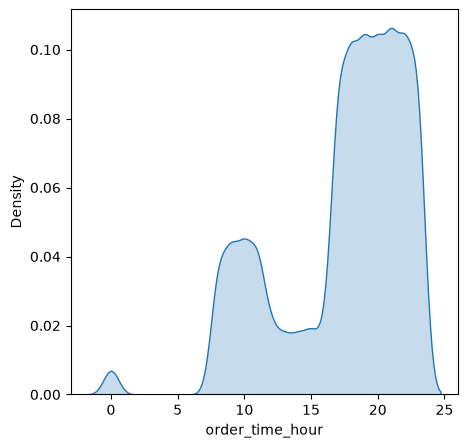

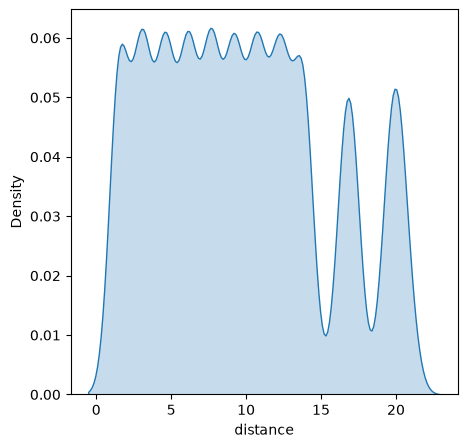

In [41]:
num_cols=df.select_dtypes(include='number').columns

for i in num_cols:
    plt.figure(figsize=(5,5))
    sns.kdeplot(data=df,x=i,fill=True)

In [42]:
df.columns

Index(['age', 'ratings', 'weather', 'traffic', 'vehicle_condition',
       'type_of_order', 'type_of_vehicle', 'multiple_deliveries', 'festival',
       'city_type', 'time_taken', 'order_day', 'order_month',
       'order_day_of_week', 'is_weekend', 'pickup_time_minutes',
       'order_time_hour', 'order_time_of_day', 'distance'],
      dtype='object')

In [43]:
df.dtypes

age                    float64
ratings                float64
weather                 object
traffic                 object
vehicle_condition        int64
type_of_order           object
type_of_vehicle         object
multiple_deliveries    float64
festival                object
city_type               object
time_taken               int64
order_day                int64
order_month              int64
order_day_of_week       object
is_weekend               int64
pickup_time_minutes    float64
order_time_hour        float64
order_time_of_day       object
distance               float64
dtype: object

In [44]:
df.isna().sum()

age                    1854
ratings                1908
weather                 525
traffic                 510
vehicle_condition         0
type_of_order             0
type_of_vehicle           0
multiple_deliveries     993
festival                228
city_type              1198
time_taken                0
order_day                 0
order_month               0
order_day_of_week         0
is_weekend                0
pickup_time_minutes    1640
order_time_hour        1640
order_time_of_day         0
distance               3630
dtype: int64

In [82]:
df['pickup_time_minutes'].unique()

array([15.,  5., 10., nan])

In [45]:
df

,age,ratings,weather,traffic,vehicle_condition,type_of_order,type_of_vehicle,multiple_deliveries,festival,city_type,time_taken,order_day,order_month,order_day_of_week,is_weekend,pickup_time_minutes,order_time_hour,order_time_of_day,distance
0,37.0,4.9,sunny,high,2,snack,motorcycle,0.0,no,urban,24,19,3,saturday,1,15.0,11.0,morning,3.025149
1,34.0,4.5,stormy,jam,2,snack,scooter,1.0,no,metropolitian,33,25,3,friday,0,5.0,19.0,evening,20.183530
2,23.0,4.4,sandstorms,low,0,drinks,motorcycle,1.0,no,urban,26,19,3,saturday,1,15.0,8.0,morning,1.552758
3,38.0,4.7,sunny,medium,0,buffet,motorcycle,1.0,no,metropolitian,21,5,4,tuesday,0,10.0,18.0,evening,7.790401
4,32.0,4.6,cloudy,high,1,snack,scooter,1.0,no,metropolitian,30,26,3,saturday,1,15.0,13.0,afternoon,6.210138
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45497,30.0,4.8,windy,high,1,meal,motorcycle,0.0,no,metropolitian,32,24,3,thursday,0,10.0,11.0,morning,1.489846
45498,21.0,4.6,windy,jam,0,buffet,motorcycle,1.0,no,metropolitian,36,16,2,wednesday,0,15.0,19.0,evening,NaN
45499,30.0,4.9,cloudy,low,1,drinks,scooter,0.0,no,metropolitian,16,11,3,friday,0,15.0,23.0,night,4.657195
45500,20.0,4.7,cloudy,high,0,snack,motorcycle,1.0,no,metropolitian,26,7,3,monday,0,5.0,13.0,afternoon,6.232393


In [9]:
num_cols=['age', 'ratings','vehicle_condition','multiple_deliveries',
          'order_day', 'order_month','is_weekend', 'pickup_time_minutes',
       'order_time_hour', 'distance']
ordinal_cols=['traffic','city_type','order_time_of_day','order_day_of_week']
nominal_cols=['weather','type_of_order','type_of_vehicle','festival']

In [10]:
ordinal_order=[['low','medium','high','jam'],['semi-urban','urban','metropolitian'],['morning', 'afternoon','evening', 'night', 'after_midnight'],['monday','tuesday','wednesday','thursday','friday','saturday', 'sunday']]

In [11]:
numeric_transformer=Pipeline([('Simple Imputer',SimpleImputer(strategy='median')),
                              ('Standard Scaling',StandardScaler()),
                             ('Power Transformer',PowerTransformer(method='yeo-johnson'))])

In [12]:
nominal_transformer=Pipeline([('Simple Imputer',SimpleImputer(strategy='most_frequent')),
                              ('One Hot Encoder',OneHotEncoder())])

In [13]:
ordinal_transformer=Pipeline([('Simple Imputer',SimpleImputer(strategy='most_frequent')),
                             ('Ordinal Encoder',OrdinalEncoder(categories=ordinal_order))])

In [62]:
numeric_transformer

,steps,"[('Simple Imputer', ...), ('Standard Scaling', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'median'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False
,copy,True


In [63]:
nominal_transformer

,steps,"[('Simple Imputer', ...), ('One Hot Encoder', ...)]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'most_frequent'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False
,categories,'auto'


In [64]:
ordinal_transformer

,steps,"[('Simple Imputer', ...), ('Ordinal Encoder', ...)]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'most_frequent'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False
,categories,"[['low', 'medium', ...], ['semi-urban', 'urban', ...], ...]"


In [14]:
preprocessing=ColumnTransformer([('Numeric Transformer',numeric_transformer,num_cols),
                                ('Nominal Transformer',nominal_transformer,nominal_cols),
                                ('Ordinal Transformer',ordinal_transformer,ordinal_cols)])

In [55]:
preprocessing

,transformers,"[('Numeric Transformer', ...), ('Nominal Transformer', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'median'
,fill_value,None


### Feature Selection

#### Best Subset Selection

In [62]:
pipe=Pipeline([('preprocessing',preprocessing),
               ('Best Subset Selection',RFE(estimator=XGBRegressor(),n_features_to_select=17))])

In [63]:
pipe.fit_transform(X_train,y_train)

array([[ 0.07021904, -0.75853496,  1.16523078, ...,  1.        ,
         2.        ,  2.        ],
       [-0.6357753 ,  1.80588755, -0.00536322, ...,  0.        ,
         2.        ,  3.        ],
       [-1.68242304, -0.05009508, -1.23246932, ...,  3.        ,
         2.        ,  2.        ],
       ...,
       [-1.16053702, -0.44976642, -0.00536322, ...,  3.        ,
         2.        ,  3.        ],
       [-1.33478398,  1.07973553, -1.23246932, ...,  3.        ,
         2.        ,  3.        ],
       [-0.81106456, -0.44976642, -0.00536322, ...,  3.        ,
         2.        ,  3.        ]], shape=(36401, 17))

In [64]:
pipe.get_feature_names_out()

array(['Numeric Transformer__age', 'Numeric Transformer__ratings',
       'Numeric Transformer__vehicle_condition',
       'Numeric Transformer__multiple_deliveries',
       'Numeric Transformer__order_time_hour',
       'Numeric Transformer__distance',
       'Nominal Transformer__weather_cloudy',
       'Nominal Transformer__weather_fog',
       'Nominal Transformer__weather_sandstorms',
       'Nominal Transformer__weather_stormy',
       'Nominal Transformer__weather_sunny',
       'Nominal Transformer__weather_windy',
       'Nominal Transformer__festival_no',
       'Nominal Transformer__city_name_DEH',
       'Ordinal Transformer__traffic', 'Ordinal Transformer__city_type',
       'Ordinal Transformer__order_time_of_day'], dtype=object)

## Step 3: Model Building

#### Linear Regression

In [94]:
model1=Pipeline([('Preprocessing',preprocessing),
                ('Linear Regression',LinearRegression())])
model1.fit(X_train,y_train)
y_pred1=model1.predict(X_test)
print('MSE:',mean_squared_error(y_test,y_pred1))
print('RMSE:',root_mean_squared_error(y_test,y_pred1))
print('MAE:',mean_absolute_error(y_test,y_pred1))
print('r2_score:',r2_score(y_test,y_pred1))

MSE: 38.93509149379775
RMSE: 6.239798994663029
MAE: 4.9803187359217
r2_score: 0.5620856286508327


#### SVR

In [22]:
model2=Pipeline([('Preprocessing',preprocessing),
                ('SVR',SVR())])
model2.fit(X_train,y_train)
y_pred2=model2.predict(X_test)
print('MSE:',mean_squared_error(y_test,y_pred2))
print('RMSE:',root_mean_squared_error(y_test,y_pred2))
print('MAE:',mean_absolute_error(y_test,y_pred2))
print('r2_score:',r2_score(y_test,y_pred2))

MSE: 29.030159970779238
RMSE: 5.387964362426615
MAE: 4.256248557933736
r2_score: 0.6734892929224359


#### KNN

In [95]:
model3=Pipeline([('Preprocessing',preprocessing),
                ('KNN',KNeighborsRegressor())])
model3.fit(X_train,y_train)
y_pred3=model3.predict(X_test)
print('MSE:',mean_squared_error(y_test,y_pred3))
print('RMSE:',root_mean_squared_error(y_test,y_pred3))
print('MAE:',mean_absolute_error(y_test,y_pred3))
print('r2_score:',r2_score(y_test,y_pred3))

MSE: 36.31889242940336
RMSE: 6.026515778574164
MAE: 4.723393033732558
r2_score: 0.5915107853578883


#### Random Forest

In [15]:
model4=Pipeline([('Preprocessing',preprocessing),
                ('Random Forest',RandomForestRegressor(n_estimators= 233,max_depth= 17,
                                                       min_samples_split=6, min_samples_leaf= 5,
                                                       max_features =0.513936073381173,max_samples=0.9290362672944653))])
model4.fit(X_train,y_train)
y_pred4=model4.predict(X_test)
print('MSE:',mean_squared_error(y_test,y_pred4))
print('RMSE:',root_mean_squared_error(y_test,y_pred4))
print('MAE:',mean_absolute_error(y_test,y_pred4))
print('r2_score:',r2_score(y_test,y_pred4))

MSE: 16.09951032513567
RMSE: 4.012419510113028
MAE: 3.177954608173686
r2_score: 0.8189240946259418


### Decision Tree Regressor

In [21]:
model5=Pipeline([('Preprocessing',preprocessing),
                ('Decision Tree',DecisionTreeRegressor())])
model5.fit(X_train,y_train)
y_pred5=model5.predict(X_test)
print('MSE:',mean_squared_error(y_test,y_pred5))
print('RMSE:',root_mean_squared_error(y_test,y_pred5))
print('MAE:',mean_absolute_error(y_test,y_pred5))
print('r2_score:',r2_score(y_test,y_pred5))

MSE: 31.723327106911327
RMSE: 5.632346500963105
MAE: 4.260630699923086
r2_score: 0.643198453781981


#### XG Boost 

In [66]:
model6=Pipeline([('Preprocessing',preprocessing),
                ('XG Boost',XGBRegressor(n_estimators=249, max_depth=10, 
                                         learning_rate= 0.023796726450909293, subsample= 0.7478387750167125, 
                                         colsample_bytree=0.9889441640501093, min_child_weight= 2, 
                                         gamma=0.5506080429217888, reg_alpha= 0.9115174930811565, 
                                         reg_lambda= 5.905222621607202))])
model6.fit(X_train,y_train)
y_pred6=model6.predict(X_test)
print('MSE:',mean_squared_error(y_test,y_pred6))
print('RMSE:',root_mean_squared_error(y_test,y_pred6))
print('MAE:',mean_absolute_error(y_test,y_pred6))
print('r2_score:',r2_score(y_test,y_pred6))

MSE: 15.587472915649414
RMSE: 3.9480974674224854
MAE: 3.1348893642425537
r2_score: 0.8246831297874451


#### K Fold Cross Validation

In [27]:
kf=KFold(n_splits=5,shuffle=True,random_state=23)

In [31]:
cross_val_score(model1,X,y,scoring='neg_mean_squared_error',cv=kf)#Linear Regression

array([-38.92043906, -38.75125798, -40.83243554, -39.3433787 ,
       -40.71728933])

In [32]:
cross_val_score(model1,X,y,scoring='neg_mean_squared_error',cv=kf).mean()

np.float64(-39.712960121045036)

In [33]:
#cross_val_score(model2,X,y,scoring='neg_mean_squared_error',cv=kf)

KeyboardInterrupt: 

In [ ]:
#cross_val_score(model2,X,y,scoring='neg_mean_squared_error',cv=kf).mean()

In [36]:
cross_val_score(model3,X,y,scoring='neg_mean_squared_error',cv=kf)

array([-42.53456983, -42.10181299, -43.66507253, -42.2992044 ,
       -43.02812747])

In [37]:
cross_val_score(model3,X,y,scoring='neg_mean_squared_error',cv=kf).mean()

np.float64(-42.72575744213593)

In [38]:
#cross_val_score(model4,X,y,scoring='neg_mean_squared_error',cv=kf)

KeyboardInterrupt: 

In [ ]:
#cross_val_score(model4,X,y,scoring='neg_mean_squared_error',cv=kf).mean()

In [40]:
cross_val_score(model5,X,y,scoring='neg_mean_squared_error',cv=kf)

array([-32.08196901, -32.33106252, -33.50395604, -32.60725275,
       -32.89758242])

In [39]:
cross_val_score(model5,X,y,scoring='neg_mean_squared_error',cv=kf).mean()

np.float64(-32.47100526810844)

In [41]:
cross_val_score(model6,X,y,scoring='neg_mean_squared_error',cv=kf)

array([-16.75508881, -17.18377304, -17.30440903, -16.74154663,
       -16.84199142])

In [42]:
cross_val_score(model6,X,y,scoring='neg_mean_squared_error',cv=kf).mean()

np.float64(-16.96536178588867)

##### Model 6 performs well cuz mean_squred error is less compare to other models.

## Step 4: Hyperparameter Tuning

#### Grid Search CV

In [17]:
search_space={'XG Boost__n_estimators': [100, 200, 300],
    'XG Boost__learning_rate': [0.01, 0.1, 0.2],
    'XG Boost__max_depth': [3, 5, 7]}
xg_b_model=Pipeline([('Preprocessing',preprocessing),
                    ('XG Boost',XGBRegressor())])
kf=KFold(n_splits=5,shuffle=True,random_state=23)
grid=GridSearchCV(estimator=xg_b_model,param_grid=search_space,scoring='r2',cv=kf)
grid.fit(X_train,y_train)

print('Best Parameters:',grid.best_params_)
print('Best MSE:',grid.best_score_)

Best Parameters: {'XG Boost__learning_rate': 0.1, 'XG Boost__max_depth': 7, 'XG Boost__n_estimators': 100}
Best MSE: 0.8126142024993896


In [20]:
# #Hyperparamter Tuning for XG Boost

def Objective(trial):

    # Search Space
    n_estimators = trial.suggest_int('n_estimators', 100, 1000)
    max_depth = trial.suggest_int('max_depth', 3, 15)
    learning_rate = trial.suggest_float('learning_rate', 0.01, 0.3)
    subsample = trial.suggest_float('subsample', 0.6, 1.0)
    colsample_bytree = trial.suggest_float('colsample_bytree', 0.6, 1.0)
    min_child_weight = trial.suggest_int('min_child_weight', 1, 10)
    gamma = trial.suggest_float('gamma', 0, 5)
    reg_alpha = trial.suggest_float('reg_alpha', 0, 1)
    reg_lambda = trial.suggest_float('reg_lambda', 0, 10)


    # Model
    xgb_model = XGBRegressor(n_estimators=n_estimators,max_depth=max_depth,learning_rate=learning_rate,
                                 subsample=subsample,colsample_bytree=colsample_bytree,min_child_weight=min_child_weight,
                                 gamma=gamma,reg_alpha=reg_alpha,reg_lambda=reg_lambda, random_state=23)


    # Pipeline
    model = Pipeline([('preprocessing', preprocessing),
        ('XGBoost', xgb_model)])


    # K-Fold
    kf = KFold(n_splits=5,shuffle=True,random_state=23)


    # Scoring
    score = cross_val_score( model,X_train,y_train,cv=kf,scoring='r2').mean()
    
    return score


# Create Study
study = optuna.create_study(direction='maximize')


# Optimize
study.optimize(Objective, n_trials=100)

[I 2026-09-29 12:39:03,821] A new study created in memory with name: no-name-245ffe65-0b03-4d6d-99c1-3ec4d42a977f
[I 2026-09-29 12:39:57,478] Trial 0 finished with value: 0.7795171976089478 and parameters: {'n_estimators': 927, 'max_depth': 4, 'learning_rate': 0.27386478325572855, 'subsample': 0.8405706608030221, 'colsample_bytree': 0.6337231970953016, 'min_child_weight': 10, 'gamma': 2.104635327644569, 'reg_alpha': 0.09091829845536392, 'reg_lambda': 2.40675866619502}. Best is trial 0 with value: 0.7795171976089478.
[I 2026-09-29 12:40:49,723] Trial 1 finished with value: 0.7762192249298095 and parameters: {'n_estimators': 513, 'max_depth': 15, 'learning_rate': 0.2446349910943408, 'subsample': 0.634395487767172, 'colsample_bytree': 0.9962850342675993, 'min_child_weight': 8, 'gamma': 2.378847061112022, 'reg_alpha': 0.9708279388463207, 'reg_lambda': 2.5757732979744405}. Best is trial 0 with value: 0.7795171976089478.
[I 2026-09-29 12:42:28,764] Trial 2 finished with value: 0.792283594608

In [21]:
print('Best Parametrs:',study.best_params)

Best Parametrs: {'n_estimators': 249, 'max_depth': 10, 'learning_rate': 0.023796726450909293, 'subsample': 0.7478387750167125, 'colsample_bytree': 0.9889441640501093, 'min_child_weight': 2, 'gamma': 0.5506080429217888, 'reg_alpha': 0.9115174930811565, 'reg_lambda': 5.905222621607202}


In [21]:
# #Hyperparameter Tuning for Random Forest Regressor

def Objective(trial):

    # Search Space
    n_estimators = trial.suggest_int('n_estimators', 100, 1000)
    max_depth = trial.suggest_int('max_depth', 3, 30)
    min_samples_split = trial.suggest_int('min_samples_split', 2, 20)
    min_samples_leaf = trial.suggest_int('min_samples_leaf', 1, 10)
    max_features = trial.suggest_float('max_features', 0.5, 1.0)
    max_samples = trial.suggest_float('max_samples', 0.5, 1.0)


    # Model
    rf_model = RandomForestRegressor(n_estimators=n_estimators,max_depth=max_depth,min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf,max_features=max_features,max_samples=max_samples,random_state=23,n_jobs=-1)


    # Pipeline
    model = Pipeline([('preprocessing', preprocessing),
        ('Random Forest', rf_model)])


    # K-Fold
    kf = KFold(n_splits=5,shuffle=True,random_state=23)


    # Scoring
    score = cross_val_score(model,X_train,y_train,cv=kf,scoring='neg_mean_squared_error').mean()


    return score


# Create Study
study = optuna.create_study(direction='maximize')

# Optimize
study.optimize(Objective, n_trials=30)

[I 2026-09-28 12:42:27,033] A new study created in memory with name: no-name-ccc506e5-baff-49eb-8c3a-cfba14fe18a7
[I 2026-09-28 12:50:33,180] Trial 0 finished with value: -16.963955656020694 and parameters: {'n_estimators': 847, 'max_depth': 25, 'min_samples_split': 2, 'min_samples_leaf': 3, 'max_features': 0.9267636263941864, 'max_samples': 0.6688054785702933}. Best is trial 0 with value: -16.963955656020694.
[I 2026-09-28 12:52:56,857] Trial 1 finished with value: -19.229769865421282 and parameters: {'n_estimators': 471, 'max_depth': 9, 'min_samples_split': 4, 'min_samples_leaf': 6, 'max_features': 0.5906017153480212, 'max_samples': 0.9771028560180453}. Best is trial 0 with value: -16.963955656020694.
[I 2026-09-28 12:53:34,405] Trial 2 finished with value: -16.76466788731718 and parameters: {'n_estimators': 113, 'max_depth': 23, 'min_samples_split': 3, 'min_samples_leaf': 9, 'max_features': 0.5080897974295057, 'max_samples': 0.5240584845250441}. Best is trial 2 with value: -16.76466

In [22]:
study.best_params

{'n_estimators': 233,
 'max_depth': 17,
 'min_samples_split': 6,
 'min_samples_leaf': 5,
 'max_features': 0.513936073381173,
 'max_samples': 0.9290362672944653}

### Bias Variance Tradeoff

In [20]:
X_train_transformed=preprocessing.fit_transform(X_train)
X_test_transformed=preprocessing.transform(X_test)
avg_expected_loss,avg_bias,avg_var=bias_variance_decomp(XGBRegressor(n_estimators=249, max_depth=10, 
                                         learning_rate= 0.023796726450909293, subsample= 0.7478387750167125, 
                                         colsample_bytree=0.9889441640501093, min_child_weight= 2, 
                                         gamma=0.5506080429217888, reg_alpha= 0.9115174930811565, 
                                         reg_lambda= 5.905222621607202),X_train_transformed,y_train,X_test_transformed,y_test)

In [21]:
avg_bias

np.float64(0.9037468410064828)

In [22]:
avg_var

np.float64(0.42558839687946376)

In [23]:
avg_expected_loss

np.float64(0.9029782441489946)

In [37]:
print("Train R2:", model6.score(X_train, y_train))
print("Test R2:", model6.score(X_test, y_test))

Train R2: 0.8870152831077576
Test R2: 0.8225711584091187


In [16]:
print('Train R2:',model4.score(X_train,y_train))
print('Train R2:',model4.score(X_test,y_test))

Train R2: 0.8853586987768332
Train R2: 0.8189240946259418


## Final Model and Pickel File

In [67]:
with open(r"C:\\Project-ML\\model.pkl",'wb') as f:
   pickle.dump(model6,f)

In [21]:
import sklearn
print(sklearn.__version__)

1.7.2
